# Improvement phase — Step 1: performance diagnosis
Separate from the frozen baseline and final evaluation. Analyze training histories and validation predictions only. No training, architecture changes, test parsing, threshold promotion, or checkpoint replacement. Test artifacts are hashed only as opaque bytes to verify preservation.
Threshold maxima below reuse validation users for selection and scoring: they are optimistic diagnostics, not new performance estimates.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'configs/improvement_step1_v1.json').exists())
sys.path.insert(0, str(ROOT))
from src.performance_diagnosis import run, verify
from IPython.display import display, Image
print(ROOT)

C:\Users\p.vazifeh\Desktop\University\Project\Bot Detection Implementation


## Protocol
Pinned manifests; canonical user_key joins; saved primary and alternative checkpoints; a fixed 101-point threshold grid from 0 to 1. Diagnostic F1 ties prefer proximity to 0.5, then the lower threshold. Preserve missing predictions. Match cohorts explicitly. Never choose a model by comparing scores on different users.
Class weights are audited from training labels and metadata. Their causal effect requires controlled retraining, which is outside this analysis. Learning-curve losses use different weighting and train/eval modes; raw gaps do not prove overfitting.

In [2]:
output_dir, tables = run(ROOT)
print('Versioned output:', output_dir)
for name in ['checkpoint_threshold_summary', 'precision_recall_tradeoffs', 'learning_curve_summary', 'class_weight_audit', 'matched_primary_validation']:
    print(name)
    display(tables[name])

Versioned output: C:\Users\p.vazifeh\Desktop\University\Project\Bot Detection Implementation\results\versions\improvement_step1_v1\20260920T111205869424Z_61a29ac9
checkpoint_threshold_summary


,model,variant,primary,validation_n,validation_bots,cohort,threshold,bot_precision,bot_recall,bot_f1,...,predicted_bots,roc_auc,average_precision,diagnostic_threshold,apparent_max_f1,diagnostic_precision,diagnostic_recall,diagnostic_fp,diagnostic_fn,status
0,baselines/tabular_lr,fitted,True,144,28,all_validation,0.5,0.350000,0.750000,0.477273,...,60,0.736145,0.481287,0.51,0.482759,0.355932,0.750000,38,7,same_validation_selection_and_scoring_optimist...
1,baselines/tabular_mlp,last,True,144,28,all_validation,0.5,0.346939,0.607143,0.441558,...,49,0.734606,0.450877,0.73,0.518519,0.538462,0.500000,12,14,same_validation_selection_and_scoring_optimist...
2,baselines/tabular_mlp,best_validation_loss,False,144,28,all_validation,0.5,0.375000,0.750000,0.500000,...,56,0.780172,0.484549,0.53,0.512195,0.388889,0.750000,33,7,same_validation_selection_and_scoring_optimist...
3,baselines/text_lr,fitted,True,144,28,all_validation,0.5,0.304348,0.750000,0.432990,...,69,0.723522,0.369559,0.54,0.512821,0.400000,0.714286,30,8,same_validation_selection_and_scoring_optimist...
4,baselines/text_mlp,last,False,144,28,all_validation,0.5,0.333333,0.392857,0.360656,...,33,0.650554,0.298287,0.14,0.425000,0.326923,0.607143,35,11,same_validation_selection_and_scoring_optimist...
5,baselines/text_mlp,best_validation_loss,True,144,28,all_validation,0.5,0.226087,0.928571,0.363636,...,115,0.720135,0.374810,0.55,0.467532,0.367347,0.642857,31,10,same_validation_selection_and_scoring_optimist...
6,graph/gcn,best_validation_loss,True,42,7,graph_and_text_available_validation,0.5,0.128205,0.714286,0.217391,...,39,0.477551,0.244015,0.49,0.285714,0.166667,1.000000,35,0,same_validation_selection_and_scoring_optimist...
7,graph/gcn,last,False,42,7,graph_and_text_available_validation,0.5,0.000000,0.000000,0.000000,...,1,0.485714,0.256620,0.49,0.333333,0.272727,0.428571,8,4,same_validation_selection_and_scoring_optimist...
8,graph_tabular/gcn_tabular,best_validation_loss,True,42,7,graph_and_text_available_validation,0.5,0.312500,0.714286,0.434783,...,16,0.865306,0.685444,0.61,0.625000,0.555556,0.714286,4,2,same_validation_selection_and_scoring_optimist...
9,graph_tabular/gcn_tabular,last,False,42,7,graph_and_text_available_validation,0.5,0.312500,0.714286,0.434783,...,16,0.865306,0.685444,0.61,0.625000,0.555556,0.714286,4,2,same_validation_selection_and_scoring_optimist...


precision_recall_tradeoffs


,model,variant,primary,validation_n,validation_bots,cohort,minimum_recall,threshold,bot_precision,bot_recall,bot_f1,tn,fp,fn,tp,predicted_bots,status
0,baselines/tabular_lr,fitted,True,144,28,all_validation,0.50,0.68,0.424242,0.500000,0.459016,97.0,19.0,14.0,14.0,33.0,diagnostic_only
1,baselines/tabular_lr,fitted,True,144,28,all_validation,0.75,0.51,0.355932,0.750000,0.482759,78.0,38.0,7.0,21.0,59.0,diagnostic_only
2,baselines/tabular_lr,fitted,True,144,28,all_validation,0.90,0.13,0.225000,0.964286,0.364865,23.0,93.0,1.0,27.0,120.0,diagnostic_only
3,baselines/tabular_mlp,last,True,144,28,all_validation,0.50,0.75,0.538462,0.500000,0.518519,104.0,12.0,14.0,14.0,26.0,diagnostic_only
4,baselines/tabular_mlp,last,True,144,28,all_validation,0.75,0.21,0.313433,0.750000,0.442105,70.0,46.0,7.0,21.0,67.0,diagnostic_only
5,baselines/tabular_mlp,last,True,144,28,all_validation,0.90,0.02,0.224138,0.928571,0.361111,26.0,90.0,2.0,26.0,116.0,diagnostic_only
6,baselines/tabular_mlp,best_validation_loss,False,144,28,all_validation,0.50,0.67,0.466667,0.500000,0.482759,100.0,16.0,14.0,14.0,30.0,diagnostic_only
7,baselines/tabular_mlp,best_validation_loss,False,144,28,all_validation,0.75,0.53,0.388889,0.750000,0.512195,83.0,33.0,7.0,21.0,54.0,diagnostic_only
8,baselines/tabular_mlp,best_validation_loss,False,144,28,all_validation,0.90,0.36,0.309524,0.928571,0.464286,58.0,58.0,2.0,26.0,84.0,diagnostic_only
9,baselines/text_lr,fitted,True,144,28,all_validation,0.50,0.54,0.400000,0.714286,0.512821,86.0,30.0,8.0,20.0,50.0,diagnostic_only


learning_curve_summary


,model,selected_variant,best_epoch,last_epoch,best_validation_loss,last_validation_loss,last_minus_best_validation_loss,epochs_after_best,training_loss_first,training_loss_last
0,baselines/tabular_mlp,last,9,50,0.918062,1.308105,0.390043,41,1.096928,0.531012
1,baselines/text_mlp,best_validation_loss,2,50,1.103565,3.200914,2.097349,48,1.074493,0.130003
2,graph/gcn,best_validation_loss,56,200,0.694203,0.695629,0.001426,144,28.854160,0.678148
3,graph_tabular/gcn_tabular,best_validation_loss,200,200,0.512442,0.512442,0.000000,0,10.582439,0.545131
4,fusion/multimodal,best_validation_loss,139,200,0.408842,0.496310,0.087468,61,7.747236,0.235130
5,ablation/tabular_text,best_validation_loss,35,200,0.386778,1.741455,1.354676,165,0.678368,0.031582
6,ablation/text_graph,best_validation_loss,37,200,0.687226,0.714990,0.027764,163,14.187325,0.685491
7,ablation/tabular_graph,best_validation_loss,198,200,0.470387,0.503811,0.033424,2,12.602894,0.461324
8,semi_supervised/labeled_control,best_validation_loss,6,50,1.336407,1.847090,0.510683,44,0.507006,0.433795
9,semi_supervised/pseudo_student,best_validation_loss,1,50,1.188318,1.654116,0.465798,49,0.601925,0.480872


class_weight_audit


,model,labeled_train_human,labeled_train_bot,bot_to_human_loss_weight,loss_type,pseudo_users,causal_weight_effect
0,baselines/tabular_lr,540,131,4.122137,balanced_logistic_loss,0,not_identifiable_without_controlled_retraining
1,baselines/tabular_mlp,540,131,4.122137,weighted_BCE,0,not_identifiable_without_controlled_retraining
2,baselines/text_lr,540,131,4.122137,balanced_logistic_loss,0,not_identifiable_without_controlled_retraining
3,baselines/text_mlp,540,131,4.122137,weighted_BCE,0,not_identifiable_without_controlled_retraining
4,graph/gcn,162,31,5.225807,weighted_CE,0,not_identifiable_without_controlled_retraining
5,graph_tabular/gcn_tabular,162,31,5.225807,weighted_CE,0,not_identifiable_without_controlled_retraining
6,fusion/multimodal,162,31,5.225807,weighted_CE,0,not_identifiable_without_controlled_retraining
7,ablation/tabular_text,162,31,5.225807,weighted_CE,0,not_identifiable_without_controlled_retraining
8,ablation/text_graph,162,31,5.225807,weighted_CE,0,not_identifiable_without_controlled_retraining
9,ablation/tabular_graph,162,31,5.225807,weighted_CE,0,not_identifiable_without_controlled_retraining


matched_primary_validation


,cohort,model,n,bots,threshold,bot_precision,bot_recall,bot_f1,tn,fp,fn,tp,predicted_bots,roc_auc,average_precision,comparison
0,all_validation,baselines/tabular_lr,144,28,0.5,0.350000,0.750000,0.477273,77,39,7,21,60,0.736145,0.481287,descriptive_not_controlled_ablation
1,all_validation,baselines/tabular_mlp,144,28,0.5,0.346939,0.607143,0.441558,84,32,11,17,49,0.734606,0.450877,descriptive_not_controlled_ablation
2,all_validation,baselines/text_lr,144,28,0.5,0.304348,0.750000,0.432990,68,48,7,21,69,0.723522,0.369559,descriptive_not_controlled_ablation
3,all_validation,baselines/text_mlp,144,28,0.5,0.226087,0.928571,0.363636,27,89,2,26,115,0.720135,0.374810,descriptive_not_controlled_ablation
4,all_validation,semi_supervised/labeled_control,144,28,0.5,0.382979,0.642857,0.480000,87,29,10,18,47,0.739840,0.478554,descriptive_not_controlled_ablation
5,all_validation,semi_supervised/pseudo_student,144,28,0.5,0.333333,0.642857,0.439024,80,36,10,18,54,0.716133,0.434114,descriptive_not_controlled_ablation
6,graph_and_text_available_validation,baselines/tabular_lr,42,7,0.5,0.500000,0.714286,0.588235,30,5,2,5,10,0.861224,0.578175,descriptive_not_controlled_ablation
7,graph_and_text_available_validation,baselines/tabular_mlp,42,7,0.5,0.285714,0.571429,0.380952,25,10,3,4,14,0.738776,0.558929,descriptive_not_controlled_ablation
8,graph_and_text_available_validation,baselines/text_lr,42,7,0.5,0.333333,1.000000,0.500000,21,14,0,7,21,0.869388,0.556181,descriptive_not_controlled_ablation
9,graph_and_text_available_validation,baselines/text_mlp,42,7,0.5,0.218750,1.000000,0.358974,10,25,0,7,32,0.865306,0.603194,descriptive_not_controlled_ablation


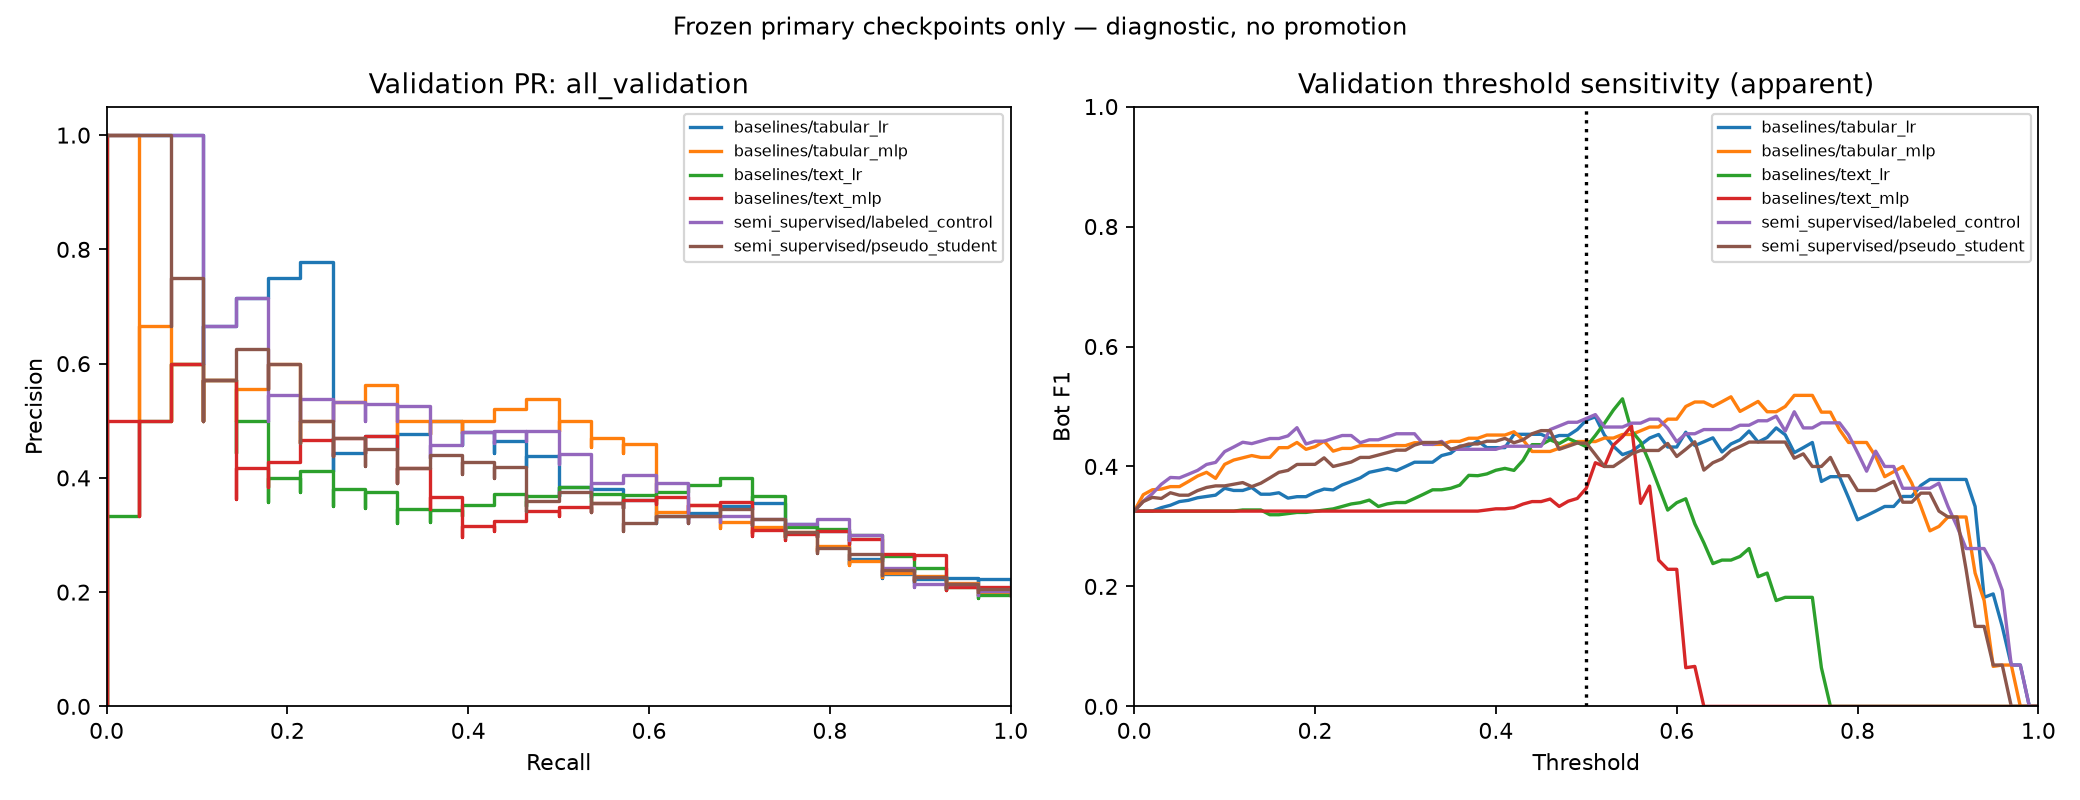

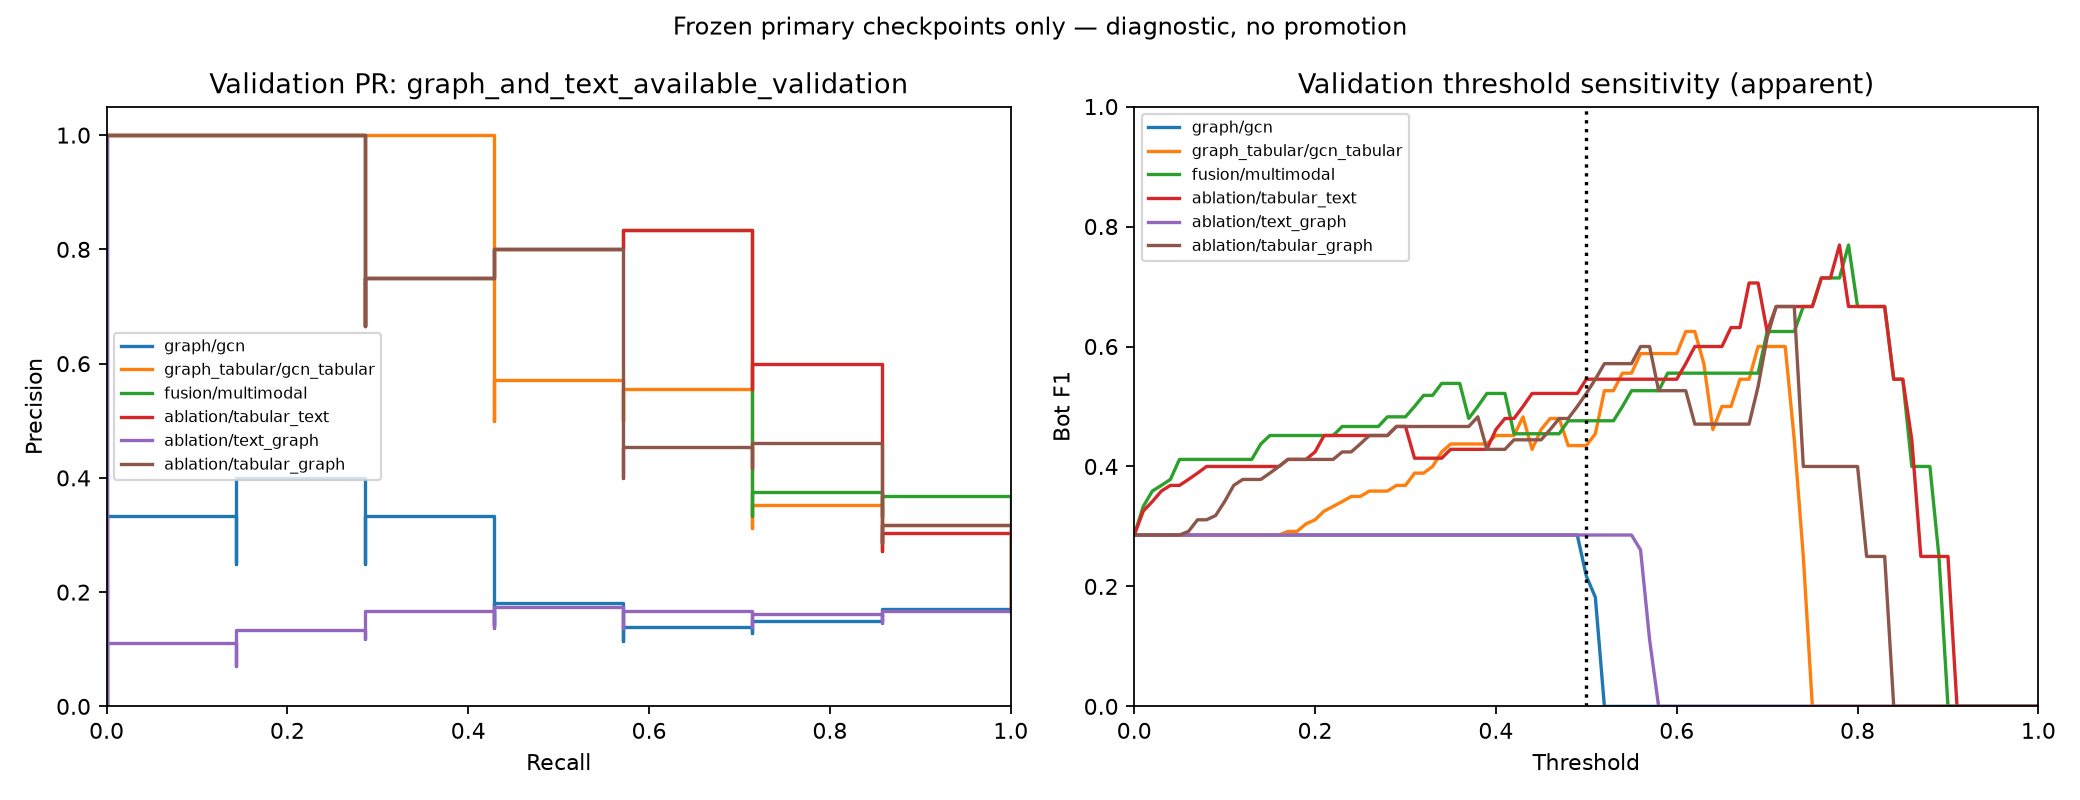

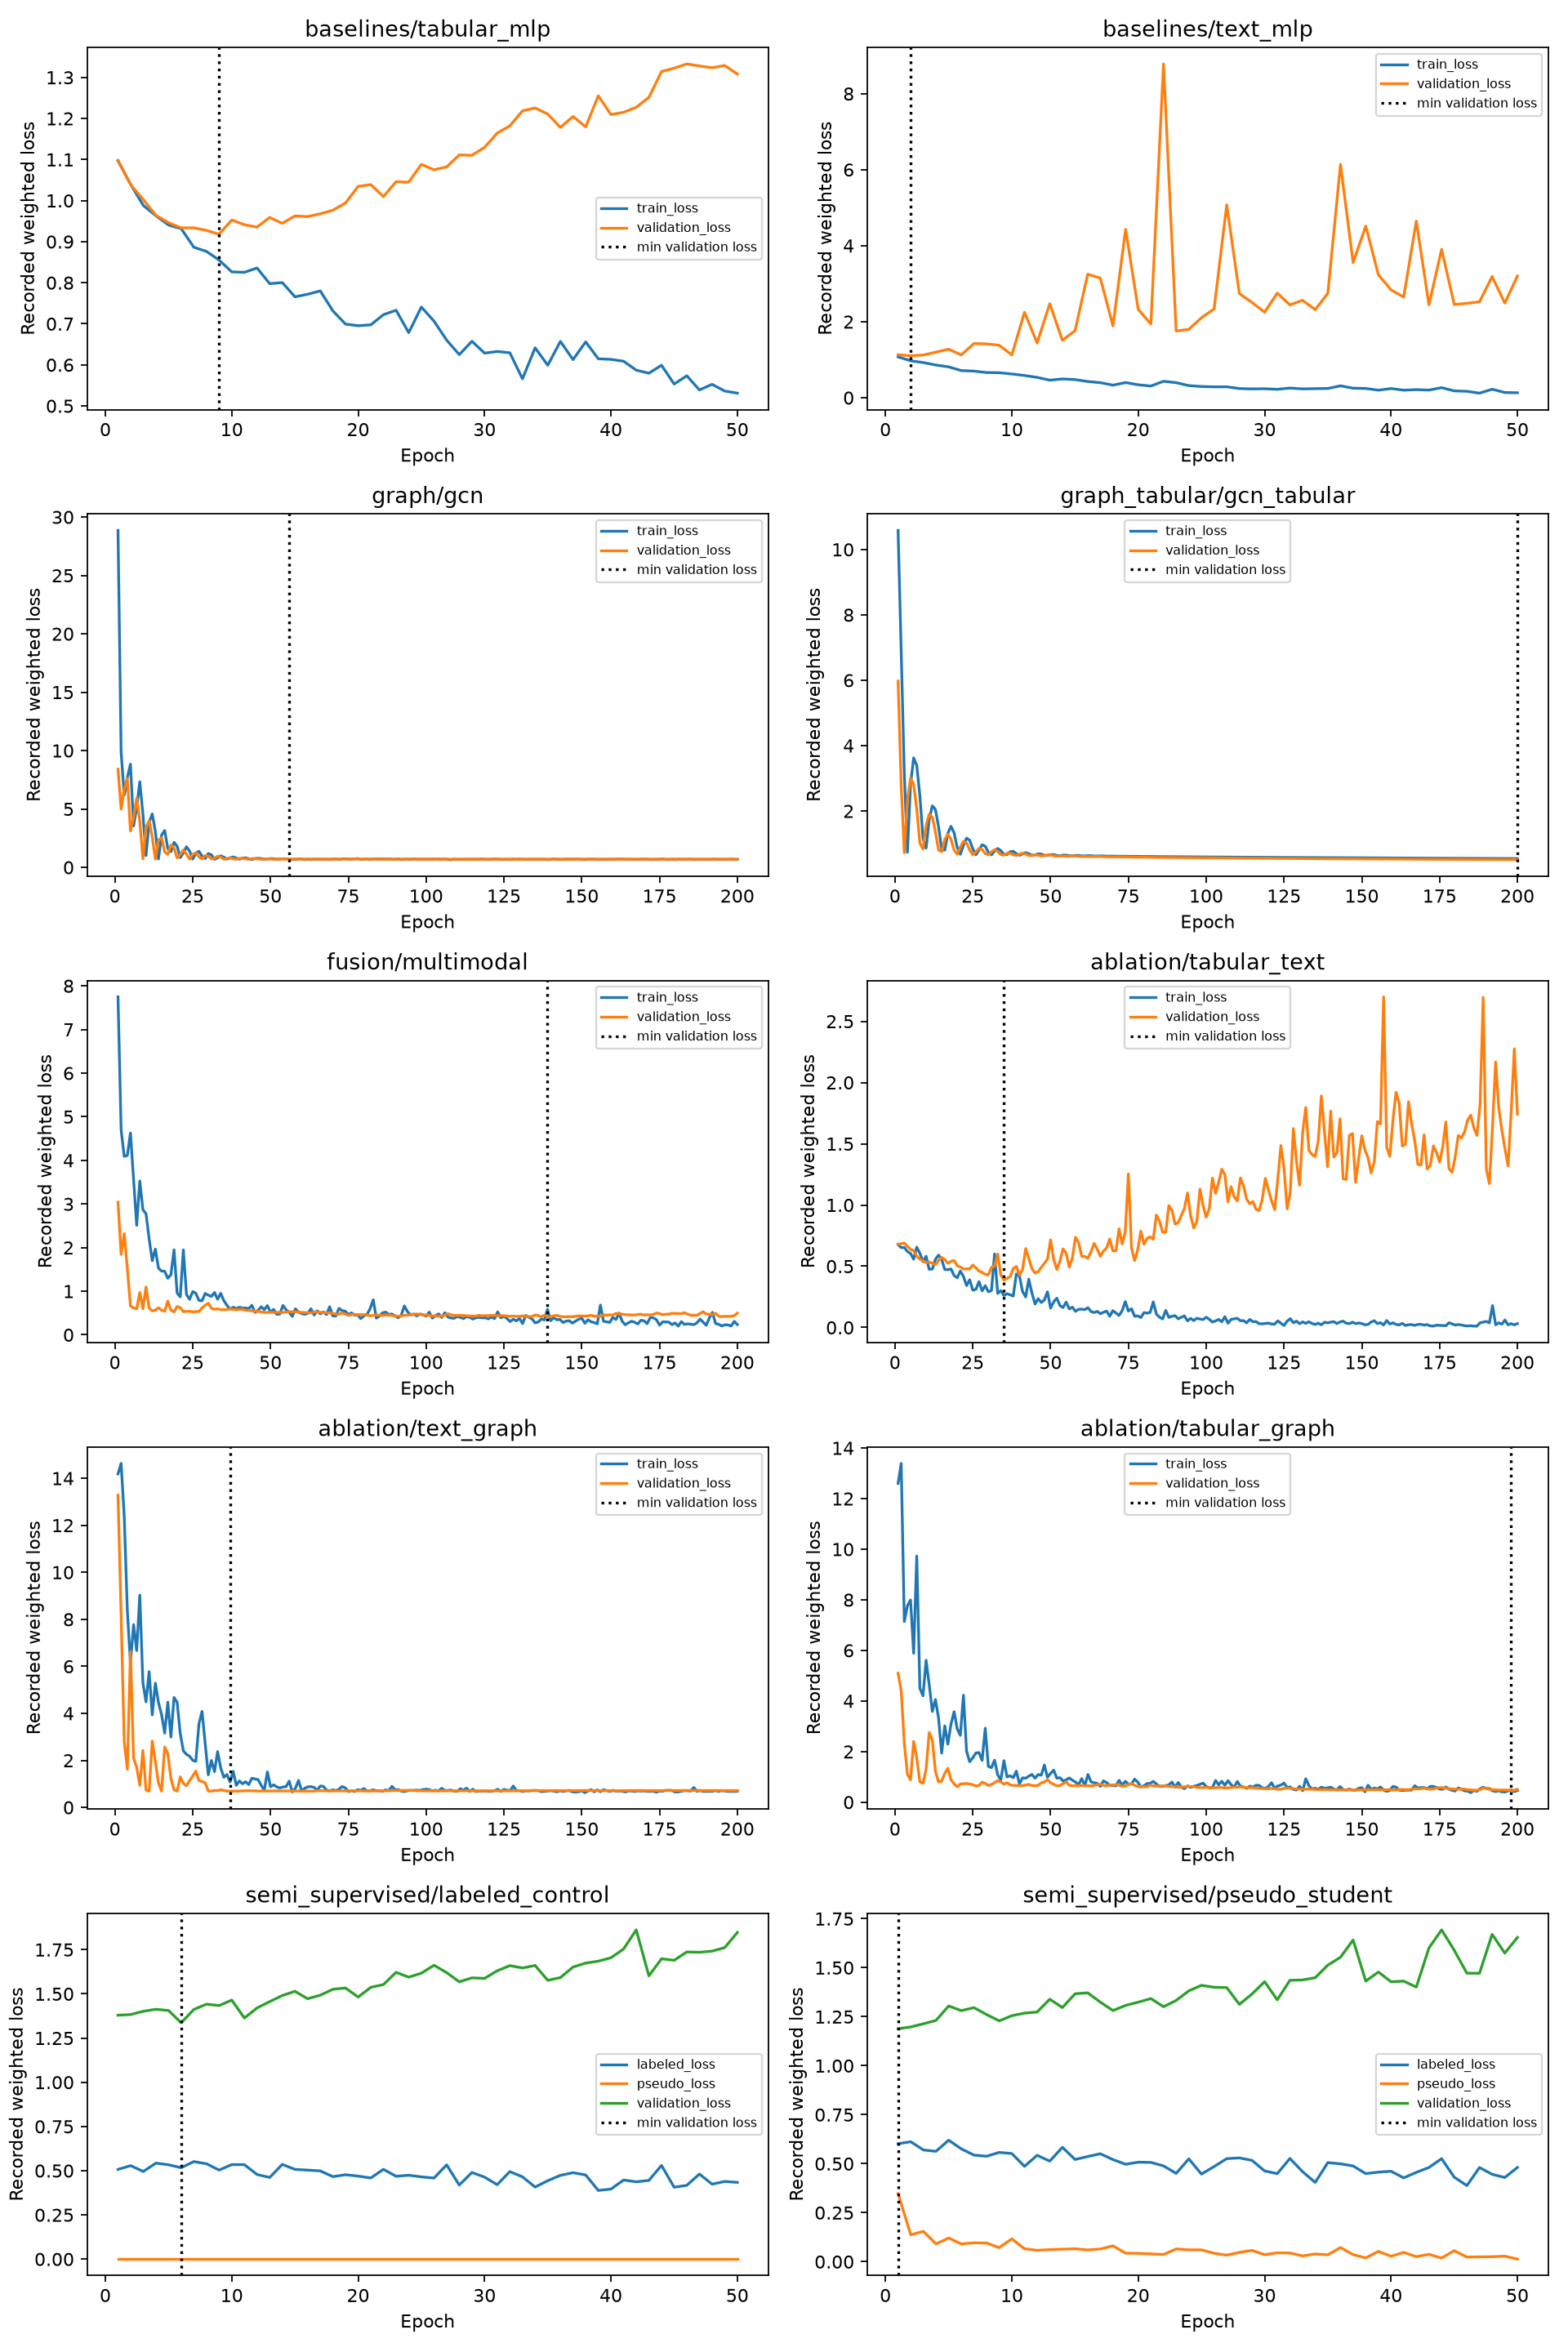

In [3]:
for path in sorted((output_dir / 'figures').glob('*.png')):
    display(Image(filename=str(path)))

In [4]:
verification = verify(ROOT, output_dir)
assert verification['test_inputs_parsed'] == 0
print(verification)

{'artifacts': 18, 'validation_checkpoint_rows': 20, 'threshold_rows': 2020, 'test_inputs_parsed': 0, 'protected_files_at_execution': 529}


## Decision boundary
No diagnostic threshold or checkpoint becomes the new primary automatically. Preserve the test protocol. Review these results before any further experiment. Graph-related validation has only seven bots; no causal class-weight claims, generalization claims, or architecture additions follow from this notebook. The original supervised teacher is the baseline tabular MLP, not an additional independent model. Semi-supervised final-checkpoint predictions were not saved and are not invented here.